# A deeper look at viewmastR

This tutorial covers training diagnostics, speed settings, the training data itself,
training once and inferring later, model weights, and the three model types. It follows
the R article [A deeper look at viewmastR](https://furlan-lab.github.io/viewmastR/articles/InDepth.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query | CD34+ enriched bone marrow, multiome RNA (Persad et al. 2023, Zenodo 6383269) |

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
label = td.config().get("greenleaf_label", "celltype")
ref = td.greenleaf_reference()
query = td.multiome_rna("cd34")
for a in (query, ref):
    vm.calculate_feature_dispersion(a)
    vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
vgr = set(vm.get_selected_features(ref))
vg = [g for g in vm.get_selected_features(query) if g in vgr]
print(f"{len(vg)} shared variable genes")

5955 shared variable genes


## Training history

With `return_type="list"`, `viewmastR()` returns the labelled query plus the training
record: accuracy and loss per epoch for the training and validation cells.

viewmastR: 5955 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 86.439% | validation accuracy 94.727%]


[epoch 2 | train accuracy 96.455% | validation accuracy 95.278%]


[epoch 3 | train accuracy 97.563% | validation accuracy 95.636%]


[epoch 4 | train accuracy 98.369% | validation accuracy 95.677%]


[epoch 5 | train accuracy 98.943% | validation accuracy 95.719%]


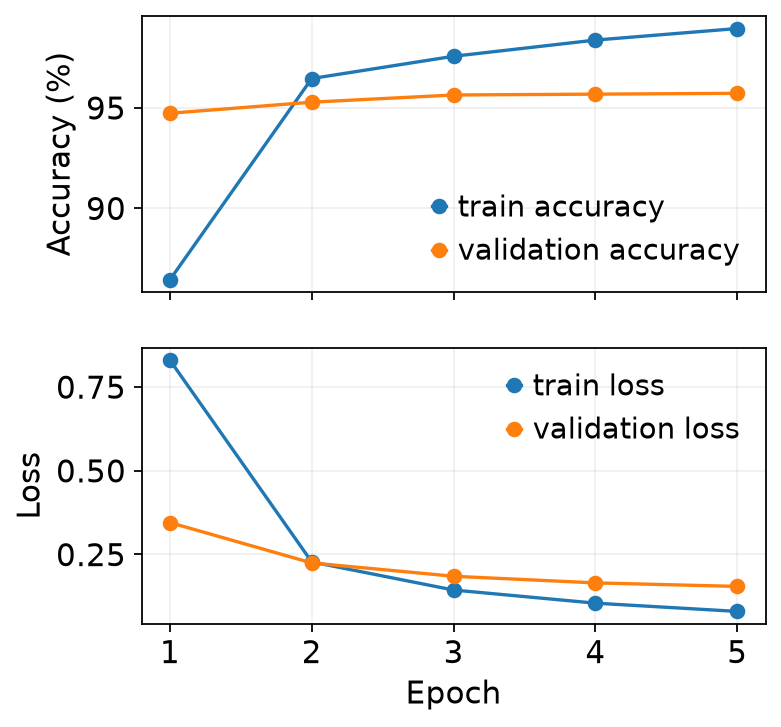

In [2]:
res = vm.viewmastR(query, ref, label, selected_features=vg, return_type="list")
vm.plot_training_data(res)
plt.show()

If training loss falls while validation loss levels off or rises, the model over-fits.
Fewer epochs (`max_epochs`) then help.

## Speed

R viewmastR offers three burn backends (`nd`, `wgpu`, `candle`). py-viewmastR runs the
`nd` (CPU) backend only, the one R uses on most servers. Speed then depends on the data
loader threads (`workers`; R uses 16). One worker plus a `seed` gives a fully reproducible
model; 16 workers reproduce R's behaviour, where batch order varies a little run to run.

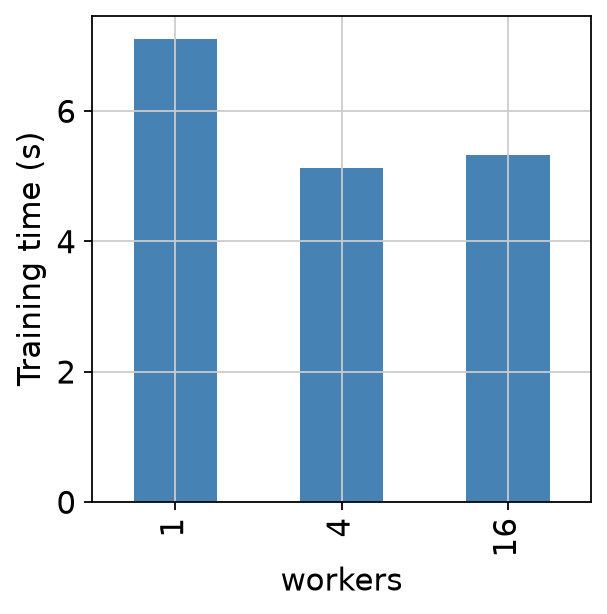

In [3]:
times = {w: vm.viewmastR(query, ref, label, selected_features=vg, max_epochs=3, workers=w,
                         return_type="list", verbose=False).seconds for w in (1, 4, 16)}
pd.Series(times, name="training seconds").rename_axis("workers").plot.bar(color="steelblue")
plt.ylabel("Training time (s)")
plt.show()

## Inspect the training data

`setup_training()` returns the normalised reference split into training and validation
cells, for use with other learning frameworks. Here it is written as Matrix Market files.

In [4]:
ts = vm.setup_training(query, ref, label, selected_features=vg, seed=1)
out = Path(tempfile.mkdtemp())
scipy.io.mmwrite(out / "train.mtx", ts.train_x)
scipy.io.mmwrite(out / "test.mtx", ts.test_x)
pd.DataFrame({"train": np.asarray(ts.labels)[ts.train_y]}).to_csv(out / "train_labels.tsv.gz", index=False)
pd.DataFrame({"test": np.asarray(ts.labels)[ts.test_y]}).to_csv(out / "test_labels.tsv.gz", index=False)
print(ts.train_x.shape, ts.test_x.shape, sorted(p.name for p in out.iterdir()))

(29054, 5955) (7264, 5955) ['test.mtx', 'test_labels.tsv.gz', 'train.mtx', 'train_labels.tsv.gz']


## Train once, infer later

`train_only=True` trains and saves the model without a query. `viewmastR_infer()` then
labels any query from the saved model.

viewmastR: 5955 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 85.902% | validation accuracy 94.796%]


[epoch 2 | train accuracy 96.396% | validation accuracy 95.595%]


[epoch 3 | train accuracy 97.481% | validation accuracy 95.870%]


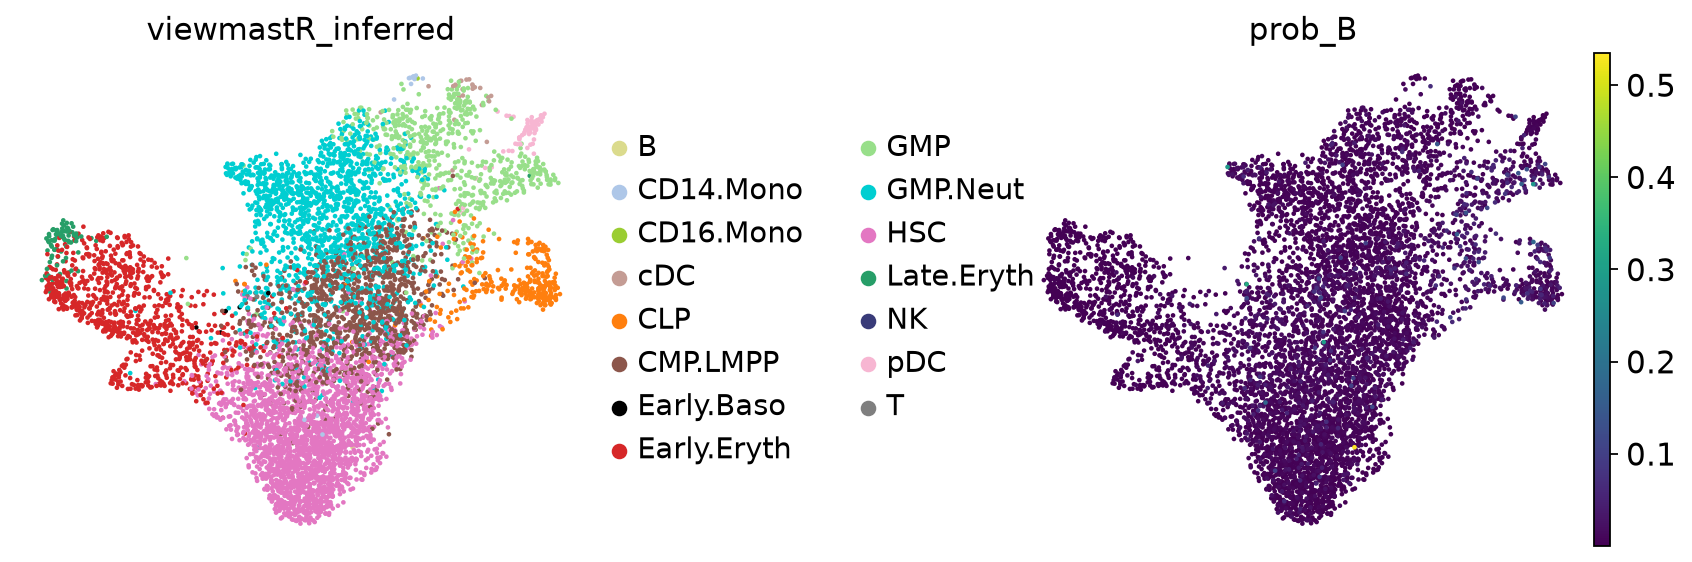

In [5]:
model_dir = Path(tempfile.mkdtemp()) / "model"
vm.viewmastR(None, ref, label, selected_features=vg, max_epochs=3, train_only=True, model_dir=model_dir)
vm.viewmastR_infer(query, model_dir, vg, return_probs=True)
prob_cols = [c for c in query.obs if c.startswith("prob_")]
vm.palette.set_colors(query, "viewmastR_inferred")
sc.pl.umap(query, color=["viewmastR_inferred", prob_cols[0]], cmap="viridis", wspace=0.6)

## Model weights

For the logistic regression (`mlr`) model, each class has one weight per gene.
`get_weights()` returns them as a genes x classes table. The 20 genes with the largest
weight for a class form a gene module; its score marks that cell type.

HSC ['MEG3', 'MYCT1', 'HEMGN', 'SOCS2', 'CLEC9A', 'KRT18', 'XXYLT1-AS2', 'RAB13', 'SCN9A', 'GBP4', 'CFH', 'GCSAML', 'BEX5', 'RIC3', 'H1F0', 'NOG', 'PCBD1', 'CTSF', 'ROBO4', 'EMCN']


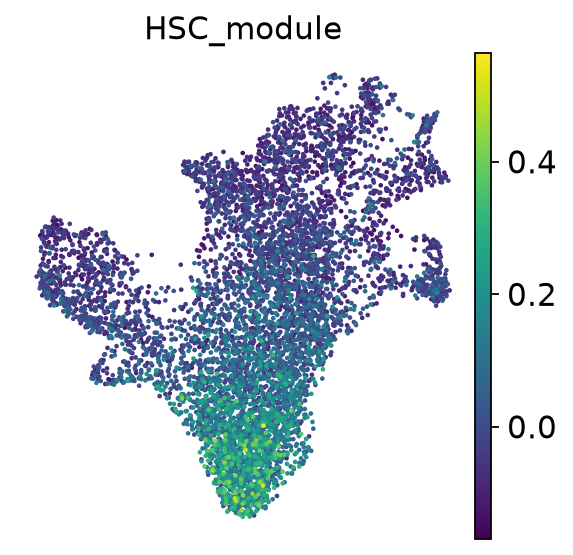

In [6]:
w = vm.get_weights(model_dir)
cls = "HSC" if "HSC" in w.columns else w.columns[0]
top = w[cls].sort_values(ascending=False).index[:20].tolist()
print(cls, top)
sc.pp.normalize_total(q := query.copy(), target_sum=1e4)
sc.pp.log1p(q)
sc.tl.score_genes(q, top, score_name=f"{cls}_module")
sc.pl.umap(q, color=f"{cls}_module", cmap="viridis")

## Algorithms

viewmastR fits three kinds of model: multinomial logistic regression (`mlr`), multinomial
naive Bayes (`nb`) and a multi-layer perceptron (`nn`, one or two hidden layers).

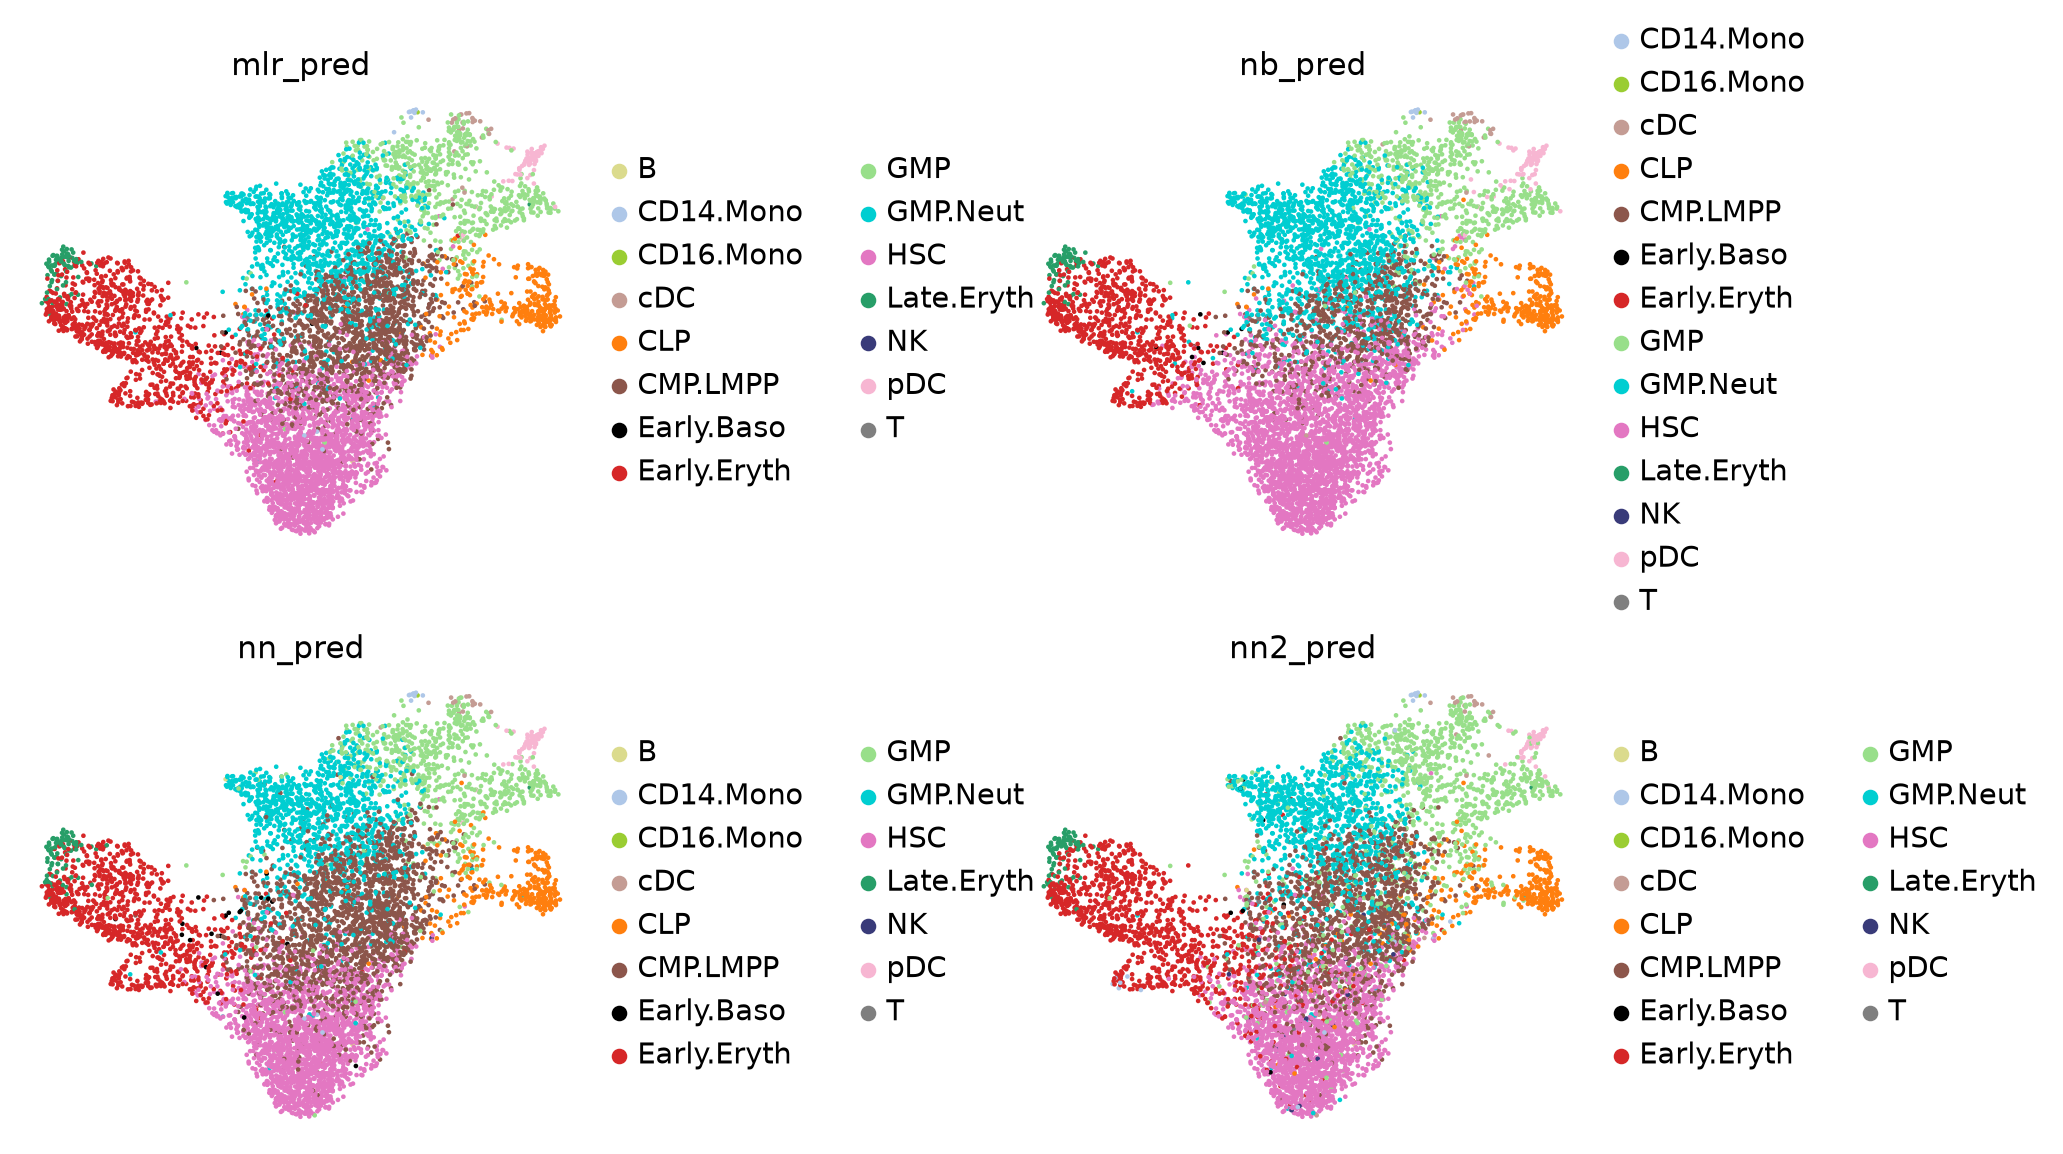

In [7]:
runs = {
    "mlr": dict(func="mlr", max_epochs=3),
    "nb": dict(func="nb"),
    "nn": dict(func="nn", hidden_layers=[200], max_epochs=3),
    "nn2": dict(func="nn", hidden_layers=[1000, 150], max_epochs=3),
}
for name, kw in runs.items():
    vm.viewmastR(query, ref, label, selected_features=vg, query_celldata_col=f"{name}_pred", verbose=False, **kw)
for n in runs:
    vm.palette.set_colors(query, f"{n}_pred")
sc.pl.umap(query, color=[f"{n}_pred" for n in runs], ncols=2, wspace=0.6)

The query authors' labels use other names, so agreement between the models is a better
comparison than accuracy here.

In [8]:
preds = query.obs[[f"{n}_pred" for n in runs]].astype(str)
agree = pd.DataFrame([[(preds[a] == preds[b]).mean() for b in preds] for a in preds],
                     index=list(runs), columns=list(runs))
print(agree.round(3).to_string())

       mlr     nb     nn    nn2
mlr  1.000  0.854  0.878  0.823
nb   0.854  1.000  0.777  0.750
nn   0.878  0.777  1.000  0.839
nn2  0.823  0.750  0.839  1.000


## Versions

In [9]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
